In [2]:
import pandas as pd
from tabulate import tabulate
import re
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df = pd.read_csv('dataset_grupo_08.csv')

In [4]:
df2= pd.get_dummies(df, columns=['target_class'], prefix='target', drop_first=False, dtype=int)
df2.head()

,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,...,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_DI,target_HY,target_N
0,Middle,Male,Obese,Never,44,0.482758,35.70,5.398540,250.000000,5.300000,...,Primary,Employed,116.000000,9.42,1.015947,160.000000,177.0,0,1,0
1,Mature,Male,Obese,Former,49,0.540230,34.97,6.500000,224.684501,7.060728,...,Secondary,Unemployed,134.331495,9.42,1.245353,111.000000,80.0,0,0,1
2,Young,Male,Underweight,Never,4,0.022989,17.64,6.000000,228.130653,7.080402,...,Tertiary,Employed,133.010050,9.42,1.156861,130.259429,126.0,0,0,1
3,Middle,Male,Underweight,Current,40,0.436781,17.30,5.421429,299.000000,9.500000,...,Primary,Employed,124.000000,9.42,1.030313,176.000000,190.0,0,1,0
4,Middle,Female,Normal,Current,27,0.287356,24.80,5.374373,277.000000,8.500000,...,Tertiary,Employed,96.000000,9.42,1.461792,143.000000,175.0,0,0,1


In [5]:
print(
    f"""
    Head Dataset

    {tabulate(
        df.head(10),
        headers="keys",
        tablefmt="grid",
        showindex=False
    )}
    """
)

print(f"""
Tail Dataset

{tabulate(
    df.tail(10),
    headers="keys",
    tablefmt="grid",
    showindex=False
)}
""")


    Head Dataset

    +-------------+----------+-------------+-----------+-------+------------------+-------+---------------+---------------+---------------+-----------------+---------------------+------------------+----------------+-----------------------+------------------------+------------------+---------------------+-------------+----------------------+---------------+----------------+------------------+---------------+--------------+---------+---------+-------------------+---------------------+------------------+--------------------+----------------+-------------------+---------------------+----------------+
| age_level   | gender   | bmi_level   | smoking   |   age |   age_normalized |   bmi |   HbA1c_level |   cholesterol |   sleep_hours |   triglycerides | physical_activity   | family_history   | stress_level   | low_hdl_cholesterol   | high_ldl_cholesterol   |   blood_pressure | sugar_consumption   |   crp_level |   homocysteine_level |   systolic_bp |   diastolic_bp |   alc

In [6]:
# ============================================================
# 1. DATA OVERVIEW
# ============================================================

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print(f"Number of observations: {df.shape[0]}")
print(f"Number of features: {df.shape[1]}")

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicated rows:")
print(df.duplicated().sum())

DATASET OVERVIEW
Number of observations: 2000
Number of features: 35

Data types:
age_level                   str
gender                      str
bmi_level                   str
smoking                     str
age                       int64
age_normalized          float64
bmi                     float64
HbA1c_level             float64
cholesterol             float64
sleep_hours             float64
triglycerides           float64
physical_activity           str
family_history              str
stress_level                str
low_hdl_cholesterol         str
high_ldl_cholesterol        str
blood_pressure          float64
sugar_consumption           str
crp_level               float64
homocysteine_level      float64
systolic_bp             float64
diastolic_bp            float64
alcohol_intake          float64
salt_intake             float64
heart_rate              float64
hdl                     float64
ldl                     float64
education_level             str
employment_status     

In [7]:
# ============================================================
# 2. VARIABLE TYPES
# ============================================================

numeric_cols = df.select_dtypes(include="number").columns
categorical_cols = df.select_dtypes(include="object").columns

print("\n" + "=" * 60)
print("VARIABLE TYPES")
print("=" * 60)

print("\nNumerical variables:")
print(list(numeric_cols))

print("\nCategorical variables:")
print(list(categorical_cols))



VARIABLE TYPES

Numerical variables:
['age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'blood_pressure', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'systolic_index', 'calcium_baseline', 'plasma_value', 'ldl_alternative', 'target_regression']

Categorical variables:
['age_level', 'gender', 'bmi_level', 'smoking', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'sugar_consumption', 'education_level', 'employment_status', 'target_class']


C:\Users\moale\AppData\Local\Temp\ipykernel_13720\2444264265.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns


In [8]:
# ============================================================
# 3. CARDINALITY
# ============================================================

print("\n" + "=" * 60)
print("CARDINALITY")
print("=" * 60)

cardinality = pd.DataFrame({
    "Unique Values": df.nunique(),
    "Unique Percentage": df.nunique() / len(df) * 100,
    "type": list(df.dtypes)
})

print(cardinality.sort_values("Unique Values"))


CARDINALITY
                      Unique Values  Unique Percentage     type
calcium_baseline                  1               0.05  float64
gender                            2               0.10      str
high_ldl_cholesterol              2               0.10      str
family_history                    2               0.10      str
low_hdl_cholesterol               2               0.10      str
physical_activity                 3               0.15      str
stress_level                      3               0.15      str
smoking                           3               0.15      str
employment_status                 3               0.15      str
education_level                   3               0.15      str
sugar_consumption                 3               0.15      str
target_class                      3               0.15      str
bmi_level                         4               0.20      str
age_level                         4               0.20      str
age                        

In [9]:
# ============================================================
# 4. DESCRIPTIVE STATISTICS - NUMERICAL VARIABLES
# ============================================================

print("\n" + "=" * 60)
print("DESCRIPTIVE STATISTICS - NUMERICAL VARIABLES")
print("=" * 60)

numeric_stats = pd.DataFrame({
    "Mean": df[numeric_cols].mean(),
    "Median": df[numeric_cols].median(),
    "Std": df[numeric_cols].std(),
    "Min": df[numeric_cols].min(),
    "Q1": df[numeric_cols].quantile(0.25),
    "Q3": df[numeric_cols].quantile(0.75),
    "Max": df[numeric_cols].max(),
    "IQR": (
        df[numeric_cols].quantile(0.75)
        - df[numeric_cols].quantile(0.25)
    ),
    "Skewness": df[numeric_cols].skew()
})

print(numeric_stats)



DESCRIPTIVE STATISTICS - NUMERICAL VARIABLES
                          Mean      Median        Std         Min          Q1  \
age                  48.262500   48.000000  21.902111    2.000000   31.000000   
age_normalized        0.531753    0.528735   0.251748    0.000000    0.333333   
bmi                  27.458071   27.320000   7.172437   12.370000   21.900000   
HbA1c_level           5.644104    5.419901   0.892513    3.500000    5.349318   
cholesterol         223.164666  224.684501  33.119872  150.000000  206.000000   
sleep_hours           6.922855    6.965654   1.350683    4.000000    6.485165   
triglycerides       182.474228  183.000000  66.655982   50.000000  137.000000   
blood_pressure      149.659168  149.587719   3.426624  120.000000  148.625000   
crp_level             7.516328    7.414141   0.913133    0.057621    7.294863   
homocysteine_level   12.520373   12.508636   0.936322    5.097473   12.304990   
systolic_bp         133.929640  134.235362  19.333587   90.0000

In [10]:
# ============================================================
# 5. DESCRIPTIVE STATISTICS - CATEGORICAL VARIABLES
# ============================================================

print("\n" + "=" * 60)
print("DESCRIPTIVE STATISTICS - CATEGORICAL VARIABLES")
print("=" * 60)

categorical_summary = []

for col in categorical_cols:
    counts = df[col].value_counts()

    categorical_summary.append({
        "Variable": col,
        "Categories": df[col].nunique(),

        "Most Frequent": counts.index[0],
        "Most Frequent Count": counts.iloc[0],
        "Most Frequent %": counts.iloc[0] / len(df) * 100,

        "Least Frequent": counts.index[-1],
        "Least Frequent Count": counts.iloc[-1],
        "Least Frequent %": counts.iloc[-1] / len(df) * 100
    })

categorical_summary = pd.DataFrame(categorical_summary)

print(categorical_summary)


DESCRIPTIVE STATISTICS - CATEGORICAL VARIABLES
                Variable  Categories Most Frequent  Most Frequent Count  \
0              age_level           4        Middle                  608   
1                 gender           2        Female                 1065   
2              bmi_level           4         Obese                  670   
3                smoking           3         Never                  933   
4      physical_activity           3          High                  923   
5         family_history           2            No                 1157   
6           stress_level           3          High                  761   
7    low_hdl_cholesterol           2            No                 1584   
8   high_ldl_cholesterol           2           Yes                 1042   
9      sugar_consumption           3           Low                  947   
10       education_level           3      Tertiary                  785   
11     employment_status           3    Unemployed  

In [11]:
# ============================================================
# 6. TARGET CLASS DISTRIBUTION
# ============================================================

print("\n" + "=" * 60)
print("TARGET CLASS DISTRIBUTION")
print("=" * 60)

class_summary = pd.DataFrame({
    "Count": df["target_class"].value_counts(),
    "Percentage": (
        df["target_class"]
        .value_counts(normalize=True) * 100
    )
})

print(class_summary)

class_ratio = (
    df["target_class"].value_counts().max()
    / df["target_class"].value_counts().min()
)

print(f"\nMajority/Minority ratio: {class_ratio:.2f}")



TARGET CLASS DISTRIBUTION
              Count  Percentage
target_class                   
N               998       49.90
HY              669       33.45
DI              333       16.65

Majority/Minority ratio: 3.00


In [12]:
# ============================================================
# 7. TARGET REGRESSION
# ============================================================

print("\n" + "=" * 60)
print("TARGET REGRESSION")
print("=" * 60)

print(df["target_regression"].describe())

print(
    f"\nSkewness: "
    f"{df['target_regression'].skew():.3f}"
)

print(
    f"Number of unique values: "
    f"{df['target_regression'].nunique()}"
)


TARGET REGRESSION
count    2000.000000
mean      133.933000
std        38.745311
min        70.000000
25%       100.000000
50%       136.000000
75%       159.000000
max       300.000000
Name: target_regression, dtype: float64

Skewness: 0.474
Number of unique values: 136


In [13]:
# ============================================================
# 8. CONSTANT VARIABLES
# ============================================================

print("\n" + "=" * 60)
print("CONSTANT VARIABLES")
print("=" * 60)

constant_cols = [
    col for col in df.columns
    if df[col].nunique() <= 1
]

if constant_cols:
    print(constant_cols)
else:
    print("No constant variables found.")


CONSTANT VARIABLES
['calcium_baseline']


In [14]:
# ============================================================
# 9. NEAR-CONSTANT VARIABLES
# ============================================================

print("\n" + "=" * 60)
print("NEAR-CONSTANT VARIABLES (>95% SAME VALUE)")
print("=" * 60)

near_constant = []

for col in df.columns:
    distribution = df[col].value_counts(normalize=True)

    if distribution.iloc[0] > 0.95:
        near_constant.append({
            "Variable": col,
            "Most Frequent Value": distribution.index[0],
            "Percentage": distribution.iloc[0] * 100
        })

near_constant = pd.DataFrame(near_constant)

if len(near_constant) > 0:
    print(near_constant)
else:
    print("No near-constant variables found.")



NEAR-CONSTANT VARIABLES (>95% SAME VALUE)
           Variable  Most Frequent Value  Percentage
0  calcium_baseline                 9.42       100.0


In [15]:
# ============================================================
# 10. OUTLIER ANALYSIS - IQR METHOD
# ============================================================

print("\n" + "=" * 60)
print("OUTLIER ANALYSIS")
print("=" * 60)

outlier_summary = []

for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    n_outliers = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()

    outlier_summary.append({
        "Variable": col,
        "Outliers": n_outliers,
        "Percentage": n_outliers / len(df) * 100
    })

outlier_summary = (
    pd.DataFrame(outlier_summary)
    .sort_values("Outliers", ascending=False)
)

print(outlier_summary)


OUTLIER ANALYSIS
              Variable  Outliers  Percentage
15                 hdl       783       39.15
16                 ldl       729       36.45
20     ldl_alternative       729       36.45
12      alcohol_intake       701       35.05
14          heart_rate       691       34.55
10         systolic_bp       683       34.15
17      systolic_index       683       34.15
13         salt_intake       646       32.30
11        diastolic_bp       604       30.20
5          sleep_hours       535       26.75
4          cholesterol       327       16.35
9   homocysteine_level       212       10.60
8            crp_level       193        9.65
3          HbA1c_level       162        8.10
7       blood_pressure       142        7.10
21   target_regression        16        0.80
19        plasma_value        12        0.60
2                  bmi         9        0.45
0                  age         0        0.00
1       age_normalized         0        0.00
6        triglycerides         0     

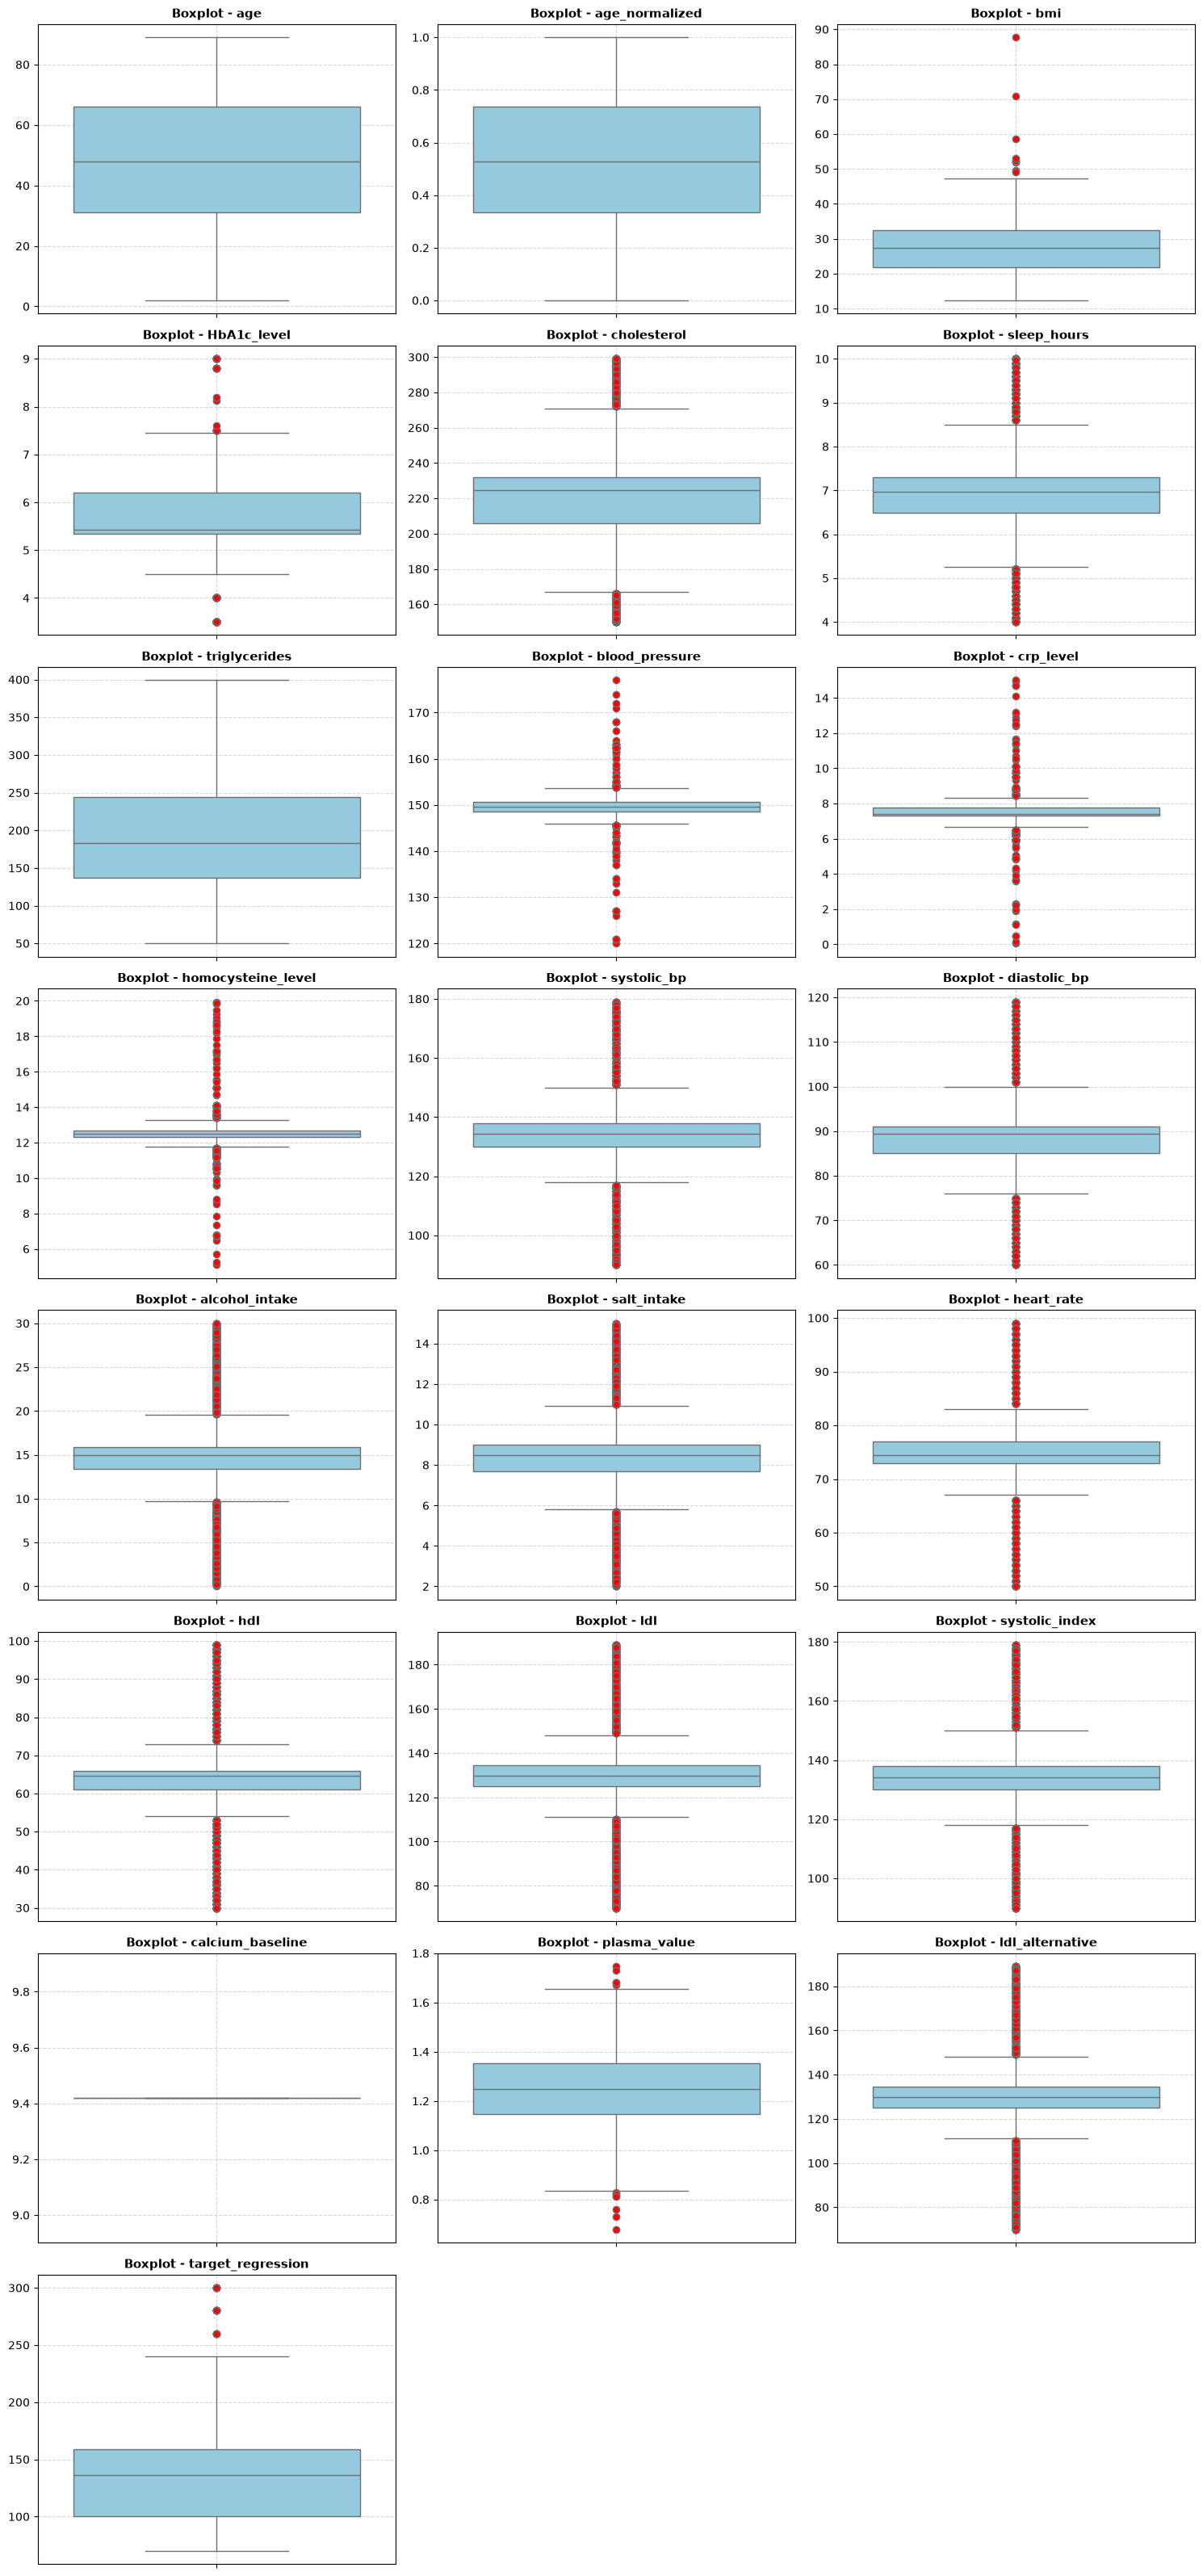

In [16]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 10.1 VISUAL OUTLIER ANALYSIS - BOXPLOTS GRID
# ============================================================

# Configuração da grelha de subplots
n_cols = 3  # Número de colunas no layout
n_vars = len(numeric_cols)
n_rows = math.ceil(n_vars / n_cols)

# Criação da figura
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4))

# Garantir que 'axes' seja uma lista/array 1D simples
if n_vars == 1:
    axes = [axes]
else:
    axes = axes.flatten()

# Plot de cada variável numérica
for i, col in enumerate(numeric_cols):
    sns.boxplot(
        y=df[col],
        ax=axes[i],
        color="skyblue",
        flierprops=dict(marker="o", markerfacecolor="red", markersize=6),
    )
    axes[i].set_title(f"Boxplot - {col}", fontsize=11, fontweight="bold")
    axes[i].set_ylabel("")
    axes[i].grid(True, linestyle="--", alpha=0.5)

# Ocultar eixos vazios/não utilizados no final da grelha
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

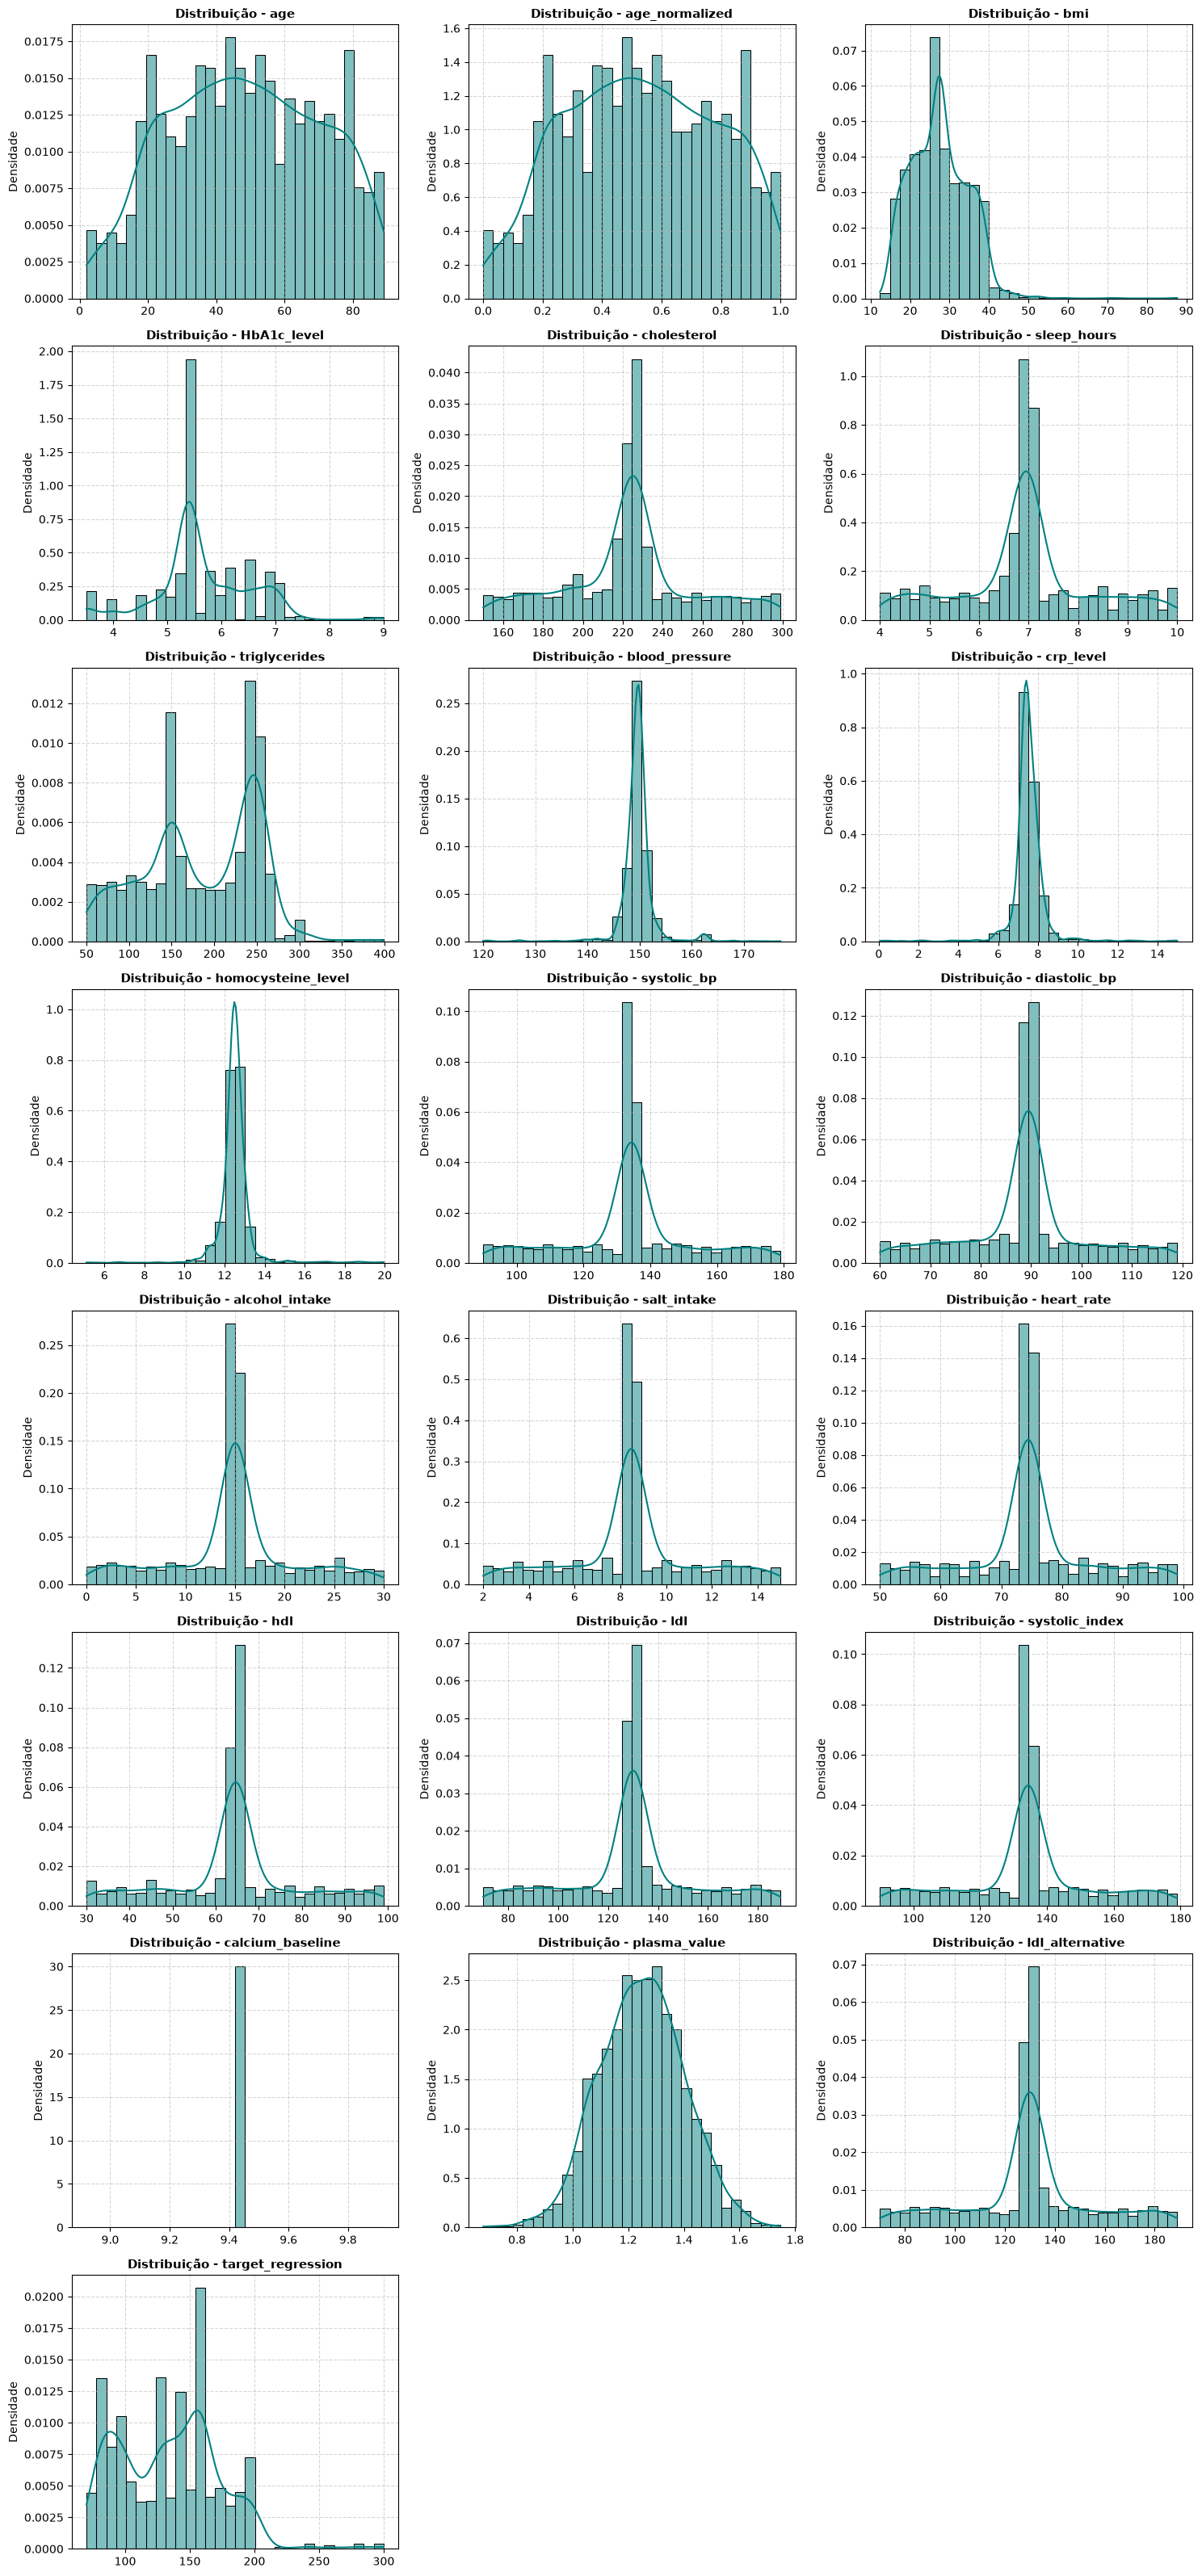

In [17]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 10.2 DISTRIBUTION ANALYSIS - HISTOGRAMS + KDE
# ============================================================

# Configuração da grelha de subplots
n_cols = 3  # Número de colunas
n_vars = len(numeric_cols)
n_rows = math.ceil(n_vars / n_cols)

# Criação da figura
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4))

# Ajuste do formato do eixos
if n_vars == 1:
    axes = [axes]
else:
    axes = axes.flatten()

# Plot dos histogramas com curva de densidade (KDE)
for i, col in enumerate(numeric_cols):
    sns.histplot(
        df[col],
        kde=True,
        ax=axes[i],
        color="teal",
        bins=30,
        stat="density",  # Permite comparar a curva KDE ajustada
    )
    axes[i].set_title(
        f"Distribuição - {col}", fontsize=11, fontweight="bold"
    )
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Densidade")
    axes[i].grid(True, linestyle="--", alpha=0.5)

# Ocultar eixos não utilizados
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


CORRELATION MATRIX
                         age  age_normalized       bmi  HbA1c_level  \
age                 1.000000        1.000000  0.096402     0.104491   
age_normalized      1.000000        1.000000  0.096402     0.104491   
bmi                 0.096402        0.096402  1.000000     0.041813   
HbA1c_level         0.104491        0.104491  0.041813     1.000000   
cholesterol         0.001560        0.001560  0.002352    -0.006744   
sleep_hours         0.028452        0.028452  0.036743    -0.012072   
triglycerides      -0.236845       -0.236845 -0.003540    -0.061578   
blood_pressure     -0.143100       -0.143101 -0.093575     0.073729   
crp_level           0.037514        0.037514 -0.096554    -0.014108   
homocysteine_level  0.050482        0.050482  0.105355    -0.001573   
systolic_bp         0.016034        0.016034 -0.017043    -0.014468   
diastolic_bp        0.010665        0.010665 -0.014707     0.002383   
alcohol_intake     -0.014907       -0.014907  0.002603   

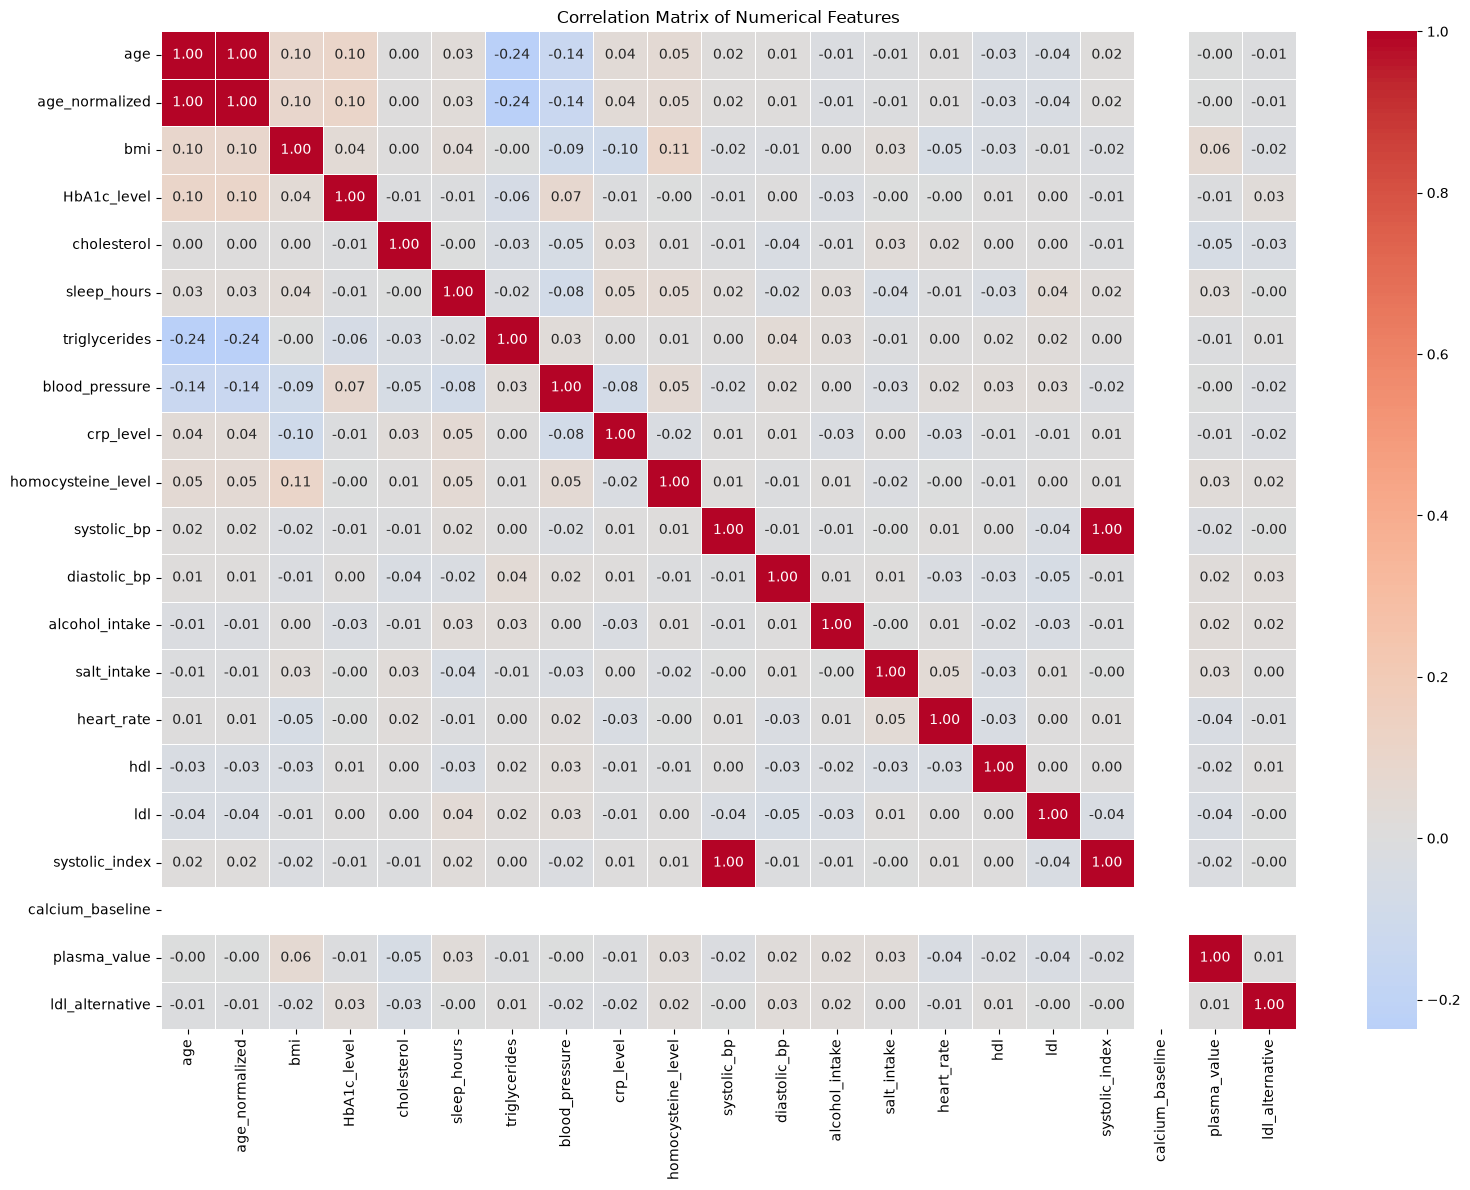

In [18]:
# ============================================================
# 11. CORRELATION MATRIX
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

print("\n" + "=" * 60)
print("CORRELATION MATRIX")
print("=" * 60)

# Remove target_regression
correlation = df[numeric_cols].drop(columns="target_regression").corr()

print(correlation)

# Heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

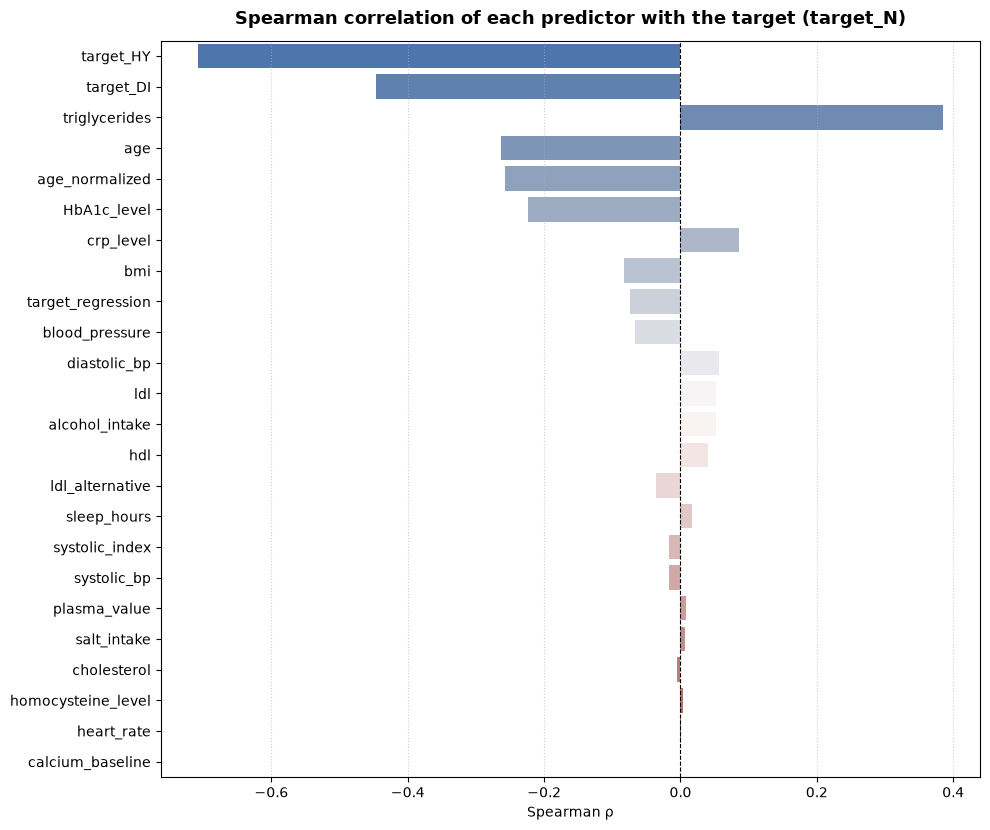

Correlation with the target, sorted by |ρ|:


,Spearman_rho,|rho|
target_HY,-0.7075,0.7075
target_DI,-0.4461,0.4461
triglycerides,0.3847,0.3847
age,-0.2637,0.2637
age_normalized,-0.2576,0.2576
HbA1c_level,-0.2239,0.2239
crp_level,0.0862,0.0862
bmi,-0.0831,0.0831
target_regression,-0.0746,0.0746
blood_pressure,-0.0660,0.0660


In [19]:
# Spearman correlation of each candidate predictor with the target (descriptive, full data)
sample_corr = df2.sample(min(len(df2), 100_000), random_state=42)
numeric_df = sample_corr.select_dtypes(include=["number"])

target_corr = (
    numeric_df.corr(method="spearman")[["target_N"]]
    .drop("target_N")
    .rename(columns={"target_N": "Spearman_rho"})
)
target_corr["|rho|"] = target_corr["Spearman_rho"].abs()
target_corr = target_corr.sort_values(by="|rho|", ascending=False)

plt.figure(figsize=(10, max(6, len(target_corr) * 0.35)))
sns.barplot(x=target_corr["Spearman_rho"], y=target_corr.index, hue=target_corr.index,
            palette="vlag", legend=False)
plt.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.title("Spearman correlation of each predictor with the target (target_N)",
          fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Spearman ρ")
plt.ylabel("")
plt.grid(axis="x", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

print("Correlation with the target, sorted by |ρ|:")
display(target_corr.round(4))

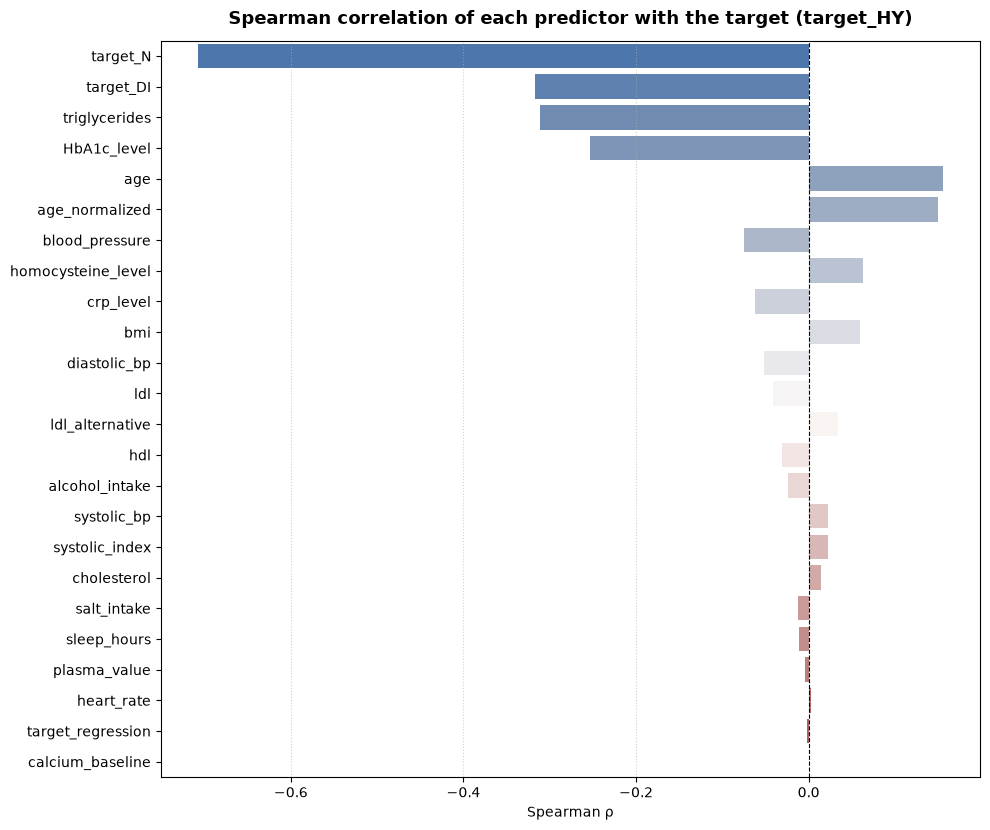

Correlation with the target, sorted by |ρ|:


,Spearman_rho,|rho|
target_N,-0.7075,0.7075
target_DI,-0.3169,0.3169
triglycerides,-0.3107,0.3107
HbA1c_level,-0.2532,0.2532
age,0.1554,0.1554
age_normalized,0.1505,0.1505
blood_pressure,-0.0750,0.0750
homocysteine_level,0.0628,0.0628
crp_level,-0.0619,0.0619
bmi,0.0597,0.0597


In [20]:
# Spearman correlation of each candidate predictor with the target (descriptive, full data)
sample_corr = df2.sample(min(len(df2), 100_000), random_state=42)
numeric_df = sample_corr.select_dtypes(include=["number"])

target_corr = (
    numeric_df.corr(method="spearman")[["target_HY"]]
    .drop("target_HY")
    .rename(columns={"target_HY": "Spearman_rho"})
)
target_corr["|rho|"] = target_corr["Spearman_rho"].abs()
target_corr = target_corr.sort_values(by="|rho|", ascending=False)

plt.figure(figsize=(10, max(6, len(target_corr) * 0.35)))
sns.barplot(x=target_corr["Spearman_rho"], y=target_corr.index, hue=target_corr.index,
            palette="vlag", legend=False)
plt.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.title("Spearman correlation of each predictor with the target (target_HY)",
          fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Spearman ρ")
plt.ylabel("")
plt.grid(axis="x", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

print("Correlation with the target, sorted by |ρ|:")
display(target_corr.round(4))

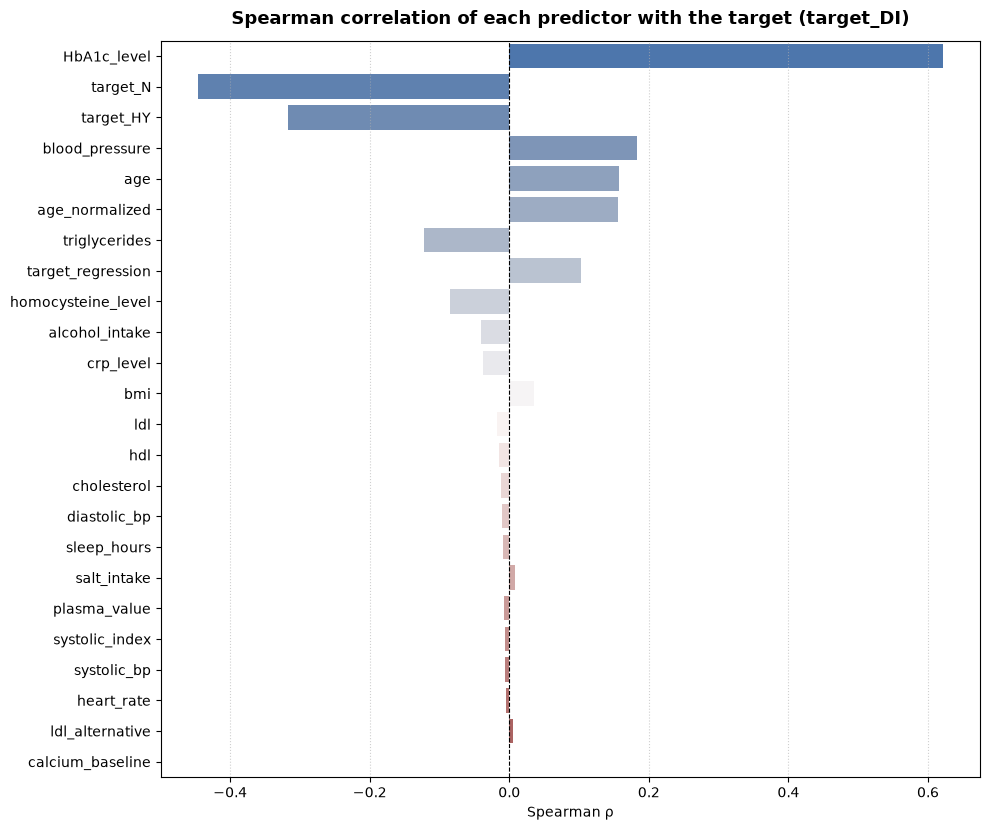

Correlation with the target, sorted by |ρ|:


,Spearman_rho,|rho|
HbA1c_level,0.6212,0.6212
target_N,-0.4461,0.4461
target_HY,-0.3169,0.3169
blood_pressure,0.1837,0.1837
age,0.1571,0.1571
age_normalized,0.1552,0.1552
triglycerides,-0.1228,0.1228
target_regression,0.1021,0.1021
homocysteine_level,-0.0848,0.0848
alcohol_intake,-0.0407,0.0407


In [21]:
# Spearman correlation of each candidate predictor with the target (descriptive, full data)
sample_corr = df2.sample(min(len(df2), 100_000), random_state=42)
numeric_df = sample_corr.select_dtypes(include=["number"])

target_corr = (
    numeric_df.corr(method="spearman")[["target_DI"]]
    .drop("target_DI")
    .rename(columns={"target_DI": "Spearman_rho"})
)
target_corr["|rho|"] = target_corr["Spearman_rho"].abs()
target_corr = target_corr.sort_values(by="|rho|", ascending=False)

plt.figure(figsize=(10, max(6, len(target_corr) * 0.35)))
sns.barplot(x=target_corr["Spearman_rho"], y=target_corr.index, hue=target_corr.index,
            palette="vlag", legend=False)
plt.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.title("Spearman correlation of each predictor with the target (target_DI)",
          fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Spearman ρ")
plt.ylabel("")
plt.grid(axis="x", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

print("Correlation with the target, sorted by |ρ|:")
display(target_corr.round(4))

In [22]:
# ============================================================
# 12. HIGHLY CORRELATED FEATURES
# ============================================================

print("\n" + "=" * 60)
print("HIGHLY CORRELATED FEATURES (|r| >= 0.80)")
print("=" * 60)

corr_pairs = (
    correlation
    .where(
        ~np.eye(
            correlation.shape[0],
            dtype=bool
        )
    )
    .stack()
    .reset_index()
)

corr_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

corr_pairs["Abs Correlation"] = (
    abs(corr_pairs["Correlation"])
)

# Remove duplicate pairs
corr_pairs["Pair"] = corr_pairs.apply(
    lambda row: tuple(
        sorted(
            [row["Feature 1"], row["Feature 2"]]
        )
    ),
    axis=1
)

high_corr = (
    corr_pairs[
        corr_pairs["Abs Correlation"] >= 0.80
    ]
    .drop_duplicates("Pair")
    .sort_values(
        "Abs Correlation",
        ascending=False
    )
    .drop(columns="Pair")
)

print(high_corr)


HIGHLY CORRELATED FEATURES (|r| >= 0.80)
       Feature 1       Feature 2  Correlation  Abs Correlation
227  systolic_bp  systolic_index          1.0              1.0
1            age  age_normalized          1.0              1.0


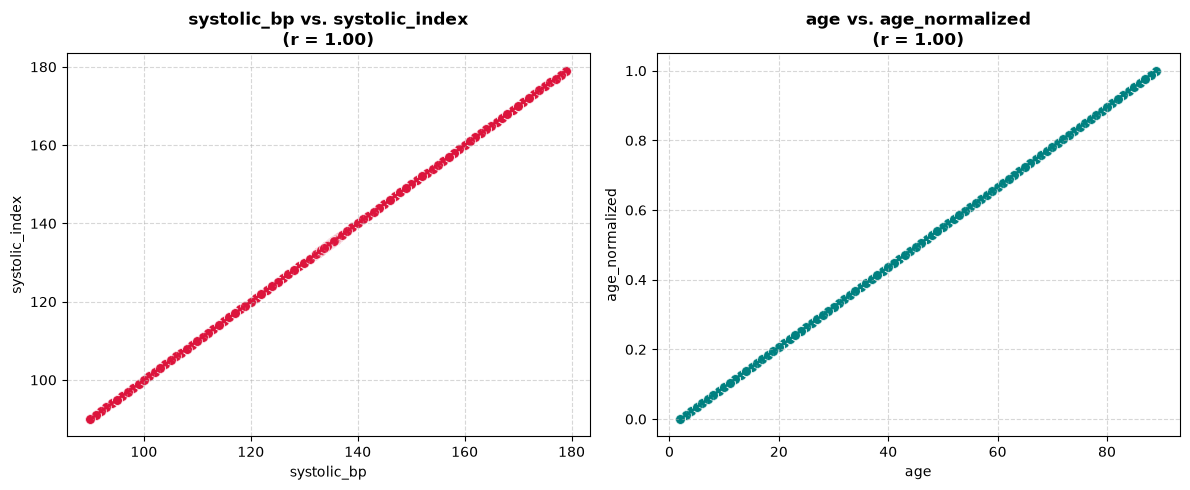

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# VISUALIZAÇÃO DE CORRELAÇÃO PERFEITA (r = 1.0)
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. Gráfico: systolic_bp vs systolic_index
sns.scatterplot(
    data=df,
    x="systolic_bp",
    y="systolic_index",
    ax=axes[0],
    color="crimson",
    s=50,
    alpha=0.8,
)
sns.regplot(
    data=df,
    x="systolic_bp",
    y="systolic_index",
    ax=axes[0],
    color="crimson",
    scatter=False,
    line_kws={"linewidth": 2},
)
axes[0].set_title(
    "systolic_bp vs. systolic_index\n(r = 1.00)", fontsize=12, fontweight="bold"
)
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Gráfico: age vs age_normalized
sns.scatterplot(
    data=df,
    x="age",
    y="age_normalized",
    ax=axes[1],
    color="teal",
    s=50,
    alpha=0.8,
)
sns.regplot(
    data=df,
    x="age",
    y="age_normalized",
    ax=axes[1],
    color="teal",
    scatter=False,
    line_kws={"linewidth": 2},
)
axes[1].set_title(
    "age vs. age_normalized\n(r = 1.00)", fontsize=12, fontweight="bold"
)
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [24]:
# ============================================================
# 13. TARGET_REGRESSION BY TARGET_CLASS
# ============================================================

print("\n" + "=" * 60)
print("TARGET_REGRESSION BY TARGET_CLASS")
print("=" * 60)

target_comparison = (
    df.groupby("target_class")["target_regression"]
    .describe()
)

print(target_comparison)


TARGET_REGRESSION BY TARGET_CLASS
              count        mean        std   min     25%    50%    75%    max
target_class                                                                 
DI            333.0  146.603604  49.499412  70.0  107.00  145.0  175.0  300.0
HY            669.0  133.136024  36.781696  70.0  101.00  133.0  163.0  200.0
N             998.0  130.239479  34.926485  71.0   96.25  130.0  158.0  200.0
